# Machine Learning Algorithm

# 1. Linear Regression Algorithm:- 
* Linar Regression Algo is a supervised learning algo used to find the relationship between between dependent and independent variables using Linear Equations
* It's find the best fit straight line on the data points.
* Examples: House Price Prediction (area -> price) etc.



### There are two types of Linear Regression Algorithm:-
1. Simple Linear Regression.
2. Multiple Linera Regression

## Simple Linear Regression:-
It is type of linear regression algorithm of supervised learning used to model to find the relationship between one independent variable (X) and one dependent variable (Y) using a linear equation 
* y = mX + b
- Where m = Slope(coef_) and b = intercept_, y = target (dependent variable), X= feature(independent variable)

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

print("All important libraries are imported")

All important libraries are imported


In [33]:
df = pd.read_csv('placement.csv')
print("Dataset is loaded Successfully!")

Dataset is loaded Successfully!


In [34]:
df.head()

,cgpa,package
0,6.89,3.26
1,5.12,1.98
2,7.82,3.25
3,7.42,3.67
4,6.94,3.57


In [ ]:
df.shape

(200, 2)

In [35]:
X = df.drop(columns = 'package')
y = df['package']

In [36]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=2)


In [11]:
X_test.head()

,cgpa
112,8.58
29,7.15
182,5.88
199,6.22
193,4.57


In [12]:
y_test.head()

112    4.10
29     3.49
182    2.08
199    2.33
193    1.94
Name: package, dtype: float64

In [37]:
lr = LinearRegression()
lr.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.56]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['cgpa']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-0.8961
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1


In [38]:
y_pred = lr.predict(X_test)

In [68]:
from sklearn.metrics import r2_score

r2_score(y_pred,y_test)



NameError: name 'y_pred' is not defined

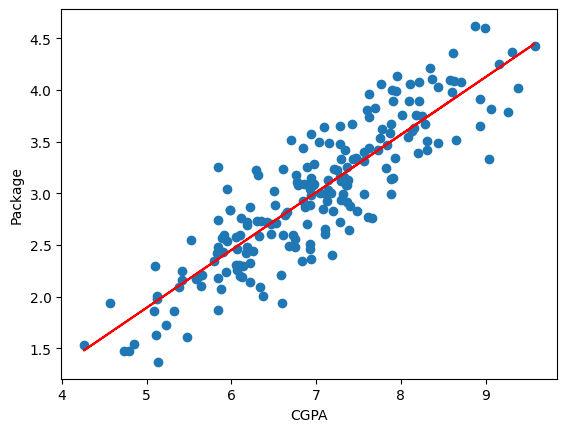

In [39]:
plt.scatter(df['cgpa'],df['package'])
plt.plot(X_train,lr.predict(X_train),color='red')
plt.xlabel("CGPA")
plt.ylabel("Package")
plt.show()

## Create Linear Regression from scratch 

### Define the code in class form

In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

# Define the class of name myLR which means MY LOGISTIC REGRESSION CLASS
class myLR:
    # Define constructure
    def __init__(self):
        self.m = None
        self.b = None
    
    # Define the fit method to train the model
    def fit(self,X_train,y_train):
        
        # Finding the slope(m) and interception (b)
        
        # m = n sigma i =1 ((Xi - meand of X)*(yi - mean of y))/(Xi - mean of X)^2
        
        # b = mean of y - m * mean of X
        
        num = 0 # Calculate the numerator for finding the m(slope of data points)
        den = 0 # Calculate the denomerator for finding the m(slope of data points)
        
        for i in range(X_train.shape[0]):
            num = num + ((X_train[i] - X_train.mean())*(y_train[i] - y_train.mean()))
            den = den + ((X_train[i] - X_train.mean())*(X_train[i] - X_train.mean()))
        
        #Calculate the m
        self.m = num/den
        
        #Calculate the b
        self.b =( y_train.mean() - (self.m*X_train.mean()))
        
        print(self.m)
        print(self.b)
    
    
    # Define the method name predict in which predict the output on test case
    def predict(self,X_test):
        # we use this formula for finding the predicted value
        
        # Formula:- y = m * X + b
        
        return self.m*X_test+ self.b 



# Load the dataset using pandas
df = pd.read_csv('placement.csv') 

# Split the feature in target and feature (X,y)
X = np.array(df.drop(columns='package'))
y = np.array(df['package'])

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)


# Create object of out class
lr = myLR()

# Train our model using fit()
lr.fit(X_train,y_train)

# Predict the outcome using predict()
pred = lr.predict(X_test)


# Find the accuracy of our model
score = r2_score(pred,y_test)
print(score)

[0.55795197]
[-0.89611192]
0.6626575570753075


# Here the simple linear regression class completed by self using the mathematically formulation and it give sames and apprx result on test case

## Multiple Linear Regression:-
In this algo dataset have more than 1 columns as input.

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_diabetes

print("All Important Libraray are imported successfully!")


All Important Libraray are imported successfully!


In [3]:
# Load Dataset
X,y = load_diabetes(return_X_y=True)

In [5]:
X.shape

(442, 10)

In [6]:
y.shape

(442,)

In [19]:
X_train,X_test,y_train,y_test = train_test_split(X,y)

In [20]:
X_train.shape

(331, 10)

In [21]:
y_train.shape

(331,)

## Now create own Linear Regression class to handle the multiple inputs

In [26]:
class myLR:
    def __init__(self):
        self.coef_=None
        self.intercept_=None
    
    def fit(self,X_train,y_train):
        X_train = np.insert(X_train,0,1,axis=1)
        
        # Calculate the coeffs
        betas = np.linalg.inv(np.dot(X_train.T,X_train)).dot(X_train.T).dot(y_train)
        self.intercept_ = betas[0]
        self.coef_ = betas[1:]
        
    
    def predict(self,X_test):
        y_pred = self.intercept_ +np.dot(X_test,self.coef_)
        return y_pred
    


In [30]:
lr = myLR()
lr.fit(X_train,y_train)
lr.predict(X_test)
print("All beta's after calculation:\n",lr.coef_)
print('Intercept Point',lr.intercept_)

All beta's after calculation:
 [  65.71203345 -220.96331555  415.34048352  338.39906534 -726.37798833
  382.12029401   -5.59896544  207.35918969  705.75895589   37.97737958]
Intercept Point 152.3480059004984


## Gradiant Descent 
It is an otimized algo in machine learning and deep learning to find the pareameters ( w and b) where the model give low error or minimeze the loss function

### It has three types
1. Batch Gradient Algo
2. Stochastic Gradient Algo
3. Mini Batch Gradient Algo

## Batch Gradient

### Objective
Implement Batch Gradient Descent using Python and NumPy to minimize the cost function of Linear Regression.

### mathematical Formula
θ_new = θ_old - Learning_Rate × Gradient

### Step1: Import all important libraries

In [32]:
# Important Libraries 
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_diabetes
from sklearn.metrics import r2_score

print("All Important Libraries are imported successfully!")

All Important Libraries are imported successfully!


## Data Loading

In [2]:
data = load_diabetes()
X = data.data
y = data.target

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

## Step 2: Create BatchGradientDescent Class

We will create our own machine learning algorithm.

### Class Responsibilities

1. Initialize weight and bias.
2. Calculate predictions.
3. Calculate Mean Squared Error.
4. Calculate gradients using the complete dataset.
5. Update weight and bias.
6. Repeat the process for specified epochs.
7. Store cost history for visualization.

### Methods

- __init__(): Initialize hyperparameters.
- predict(): Calculate predictions.
- compute_cost(): Calculate MSE.
- fit(): Train the model using Batch Gradient Descent.

In [3]:
class BGD:
    def __init__(self,lr=0.01, epoch=100):
        self.lr = lr
        self.epoch = epoch
        self.w = 0
        self.b = 0
        
        self.loss = []
        
    def predict(self,X_test):
        return np.dot(X_test,self.w) + self.b
    
    def fit(self,X_train,y_train):
        m = len(X_train)
        
        # inilialize the weights and bias
        self.b = 0 #Intercept
        self.w =np.ones(X_train.shape[1])  # coefficient
        for i in range(self.epoch):
            # Calculate the predicted values
            y_pred = np.dot(X_train,self.w) + self.b
                    
            # Calculate the gradients
            dw = -2 * np.dot((y_train - y_pred),X_train )/X_train.shape[0]
            db = -2 * np.mean(y_train - y_pred)
                    
            # Update the w and b
            self.w = self.w - (self.lr*dw)
            self.b = self.b - (self.lr*db)
        
        print(self.w,self.b)
            
        
    

In [9]:
model = BGD(epoch=500, lr=0.1)
model.fit(X_train,y_train)
pred = model.predict(X_test)

r_score = r2_score(pred,y_test)
print("R2 Score of our model is:",r_score)

[ 50.61655097  -0.92864384 165.01987168 124.52845806  40.90380061
  25.32364879 -96.29788197  93.94879167 157.87930964  87.31014873] 151.53233878908244
R2 Score of our model is: -4.188538099333538


# Stochastic Gradient Descent (SGD) From Scratch

## Objective
Implement Stochastic Gradient Descent for Linear Regression
using Python and NumPy.

### What is SGD?

Stochastic Gradient Descent is an optimization algorithm that
updates model parameters using only ONE randomly selected
training sample at a time.

### Mathematical Equation

Prediction:

    y_hat = wx + b

Loss Function:

    L(w,b) = (y_hat - y)^2

Gradient w.r.t Weight:

    dw = 2x(y_hat - y)

Gradient w.r.t Bias:

    db = 2(y_hat - y)

Weight Update:

    w = w - learning_rate * dw

Bias Update:

    b = b - learning_rate * db

### Hyperparameters

- learning_rate: Controls the update step size.
- epochs: Number of complete passes over the dataset.

In [33]:
data = load_diabetes()
X = data.data
y = data.target
print("Data Loaded Successfully!")
print("Shape of X:",X.shape)
print("Shape of y:",y.shape)

Data Loaded Successfully!
Shape of X: (442, 10)
Shape of y: (442,)


In [34]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2, random_state=42)
print("Shape of X_train:",X_train.shape)
print("Shape of X_test:",X_test.shape)
print("Shape of y_train:",y_train.shape)
print("Shape of y_test:",y_test.shape)

Shape of X_train: (353, 10)
Shape of X_test: (89, 10)
Shape of y_train: (353,)
Shape of y_test: (89,)


## Step 2: Create StochasticGradientDescent Class

We will implement SGD without using Scikit-learn.

### Class Responsibilities

1. Initialize weight and bias.
2. Calculate predictions.
3. Calculate Mean Squared Error.
4. Shuffle the training dataset.
5. Select one training sample at a time.
6. Calculate gradients for that sample.
7. Update weight and bias immediately.
8. Repeat the process for multiple epochs.

### Methods

- __init__(): Initialize hyperparameters.
- predict(): Calculate predictions.
- compute_cost(): Calculate MSE.
- fit(): Train the model using SGD.

### Important

Unlike Batch Gradient Descent, SGD updates parameters
after every individual training sample.

In [22]:
class SGD:

    def __init__(self, learning_rate=0.01, epochs=1000):

        self.learning_rate = learning_rate
        self.epochs = epochs

        self.w = None
        self.b = 0

        self.cost_history = []

    # Step 1: Prediction
    def predict(self, X_test):

        return np.dot(X_test,self.w) + self.b

    # Step 2: Calculate Cost Function
    def compute_cost(self, X, y):

        m = len(X)

        y_pred = self.predict(X)

        cost =  np.mean((y_pred - y) ** 2)

        return cost

    # Step 3: Training using SGD
    def fit(self, X_train, y_train):

        m,n = X_train.shape

        # Initialize parameters
        self.w = np.zeros(n)
        self.b = 0

        self.cost_history = []

        for epoch in range(self.epochs):

            # Shuffle dataset
            indices = np.random.permutation(m)

            X_shuffled = X_train[indices]
            y_shuffled = y_train[indices]

            # Iterate over individual samples
            for i in range(m):

                # Select one sample
                x_i = X_shuffled[i]
                y_i = y_shuffled[i]

                # Predict for one sample
                y_pred = np.dot(self.w, x_i) + self.b

                # Calculate gradients
                dw = 2 * x_i * (y_pred - y_i)

                db = 2 * (y_pred - y_i)

                # Update parameters immediately
                self.w = self.w - self.learning_rate * dw

                self.b = self.b - self.learning_rate * db

            # Calculate full dataset cost after each epoch
            cost = self.compute_cost(X_train, y_train)

            self.cost_history.append(cost)

            # Print training progress
            if epoch % 100 == 0:

                print(
                    f"Epoch: {epoch}, "
                    f"Weight:{self.w}, "
                    f"Bias: {self.b:.4f}, "
                    f"Cost: {cost:.6f}"
                )

        return self

In [29]:
model = SGD(learning_rate=0.1, epochs=100)

model.fit(X_train, y_train)

Epoch: 0, Weight:[ 36.75855635  -3.12218024 126.66004952 100.31786031  30.35800235
  18.39873239 -76.18848079  80.72660476 113.30064406  73.66741247], Bias: 173.3316, Cost: 4764.937698


In [30]:
y_pred = model.predict(X_test)

print("Actual Shape:", y_test.shape)

print("Predicted Shape:", y_pred.shape)

Actual Shape: (89,)
Predicted Shape: (89,)


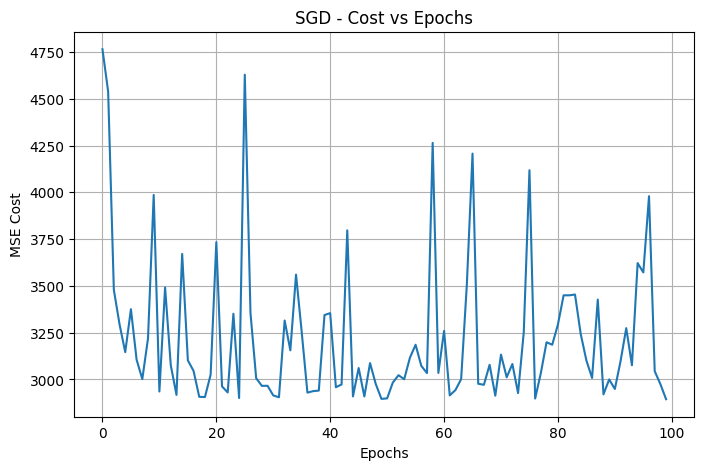

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(model.cost_history)

plt.xlabel("Epochs")

plt.ylabel("MSE Cost")

plt.title("SGD - Cost vs Epochs")

plt.grid(True)

plt.show()

## SGD regressor using sklearn

In [73]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_regression
from sklearn.linear_model import SGDRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline

from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error

print   ("All Important Libraries are imported successfully!")

All Important Libraries are imported successfully!


In [70]:
# Generate synthetic regression dataset
X,y = make_regression(n_samples=1000, n_features=5, noise=20, random_state=42)

print("Shape of X:",X.shape)
print("Shape of y:",y.shape)

Shape of X: (1000, 5)
Shape of y: (1000,)


In [72]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2, random_state= 42 )

print("Shape of X_train:",X_train.shape)
print("Shape of X_test:",X_test.shape)
print("Shape of y_train:",y_train.shape)
print("Shape of y_test:",y_test.shape)

Shape of X_train: (800, 5)
Shape of X_test: (200, 5)
Shape of y_train: (800,)
Shape of y_test: (200,)


In [74]:
sgd = make_pipeline(StandardScaler(),
                    SGDRegressor(max_iter=1000, # Maximum number of epoch
                                learning_rate="constant", # Learning rate schedule
                                eta0=0.01, # Initial Learning rate
                                random_state=42, # Reproducibility
                                tol=1e-3) #Stopping tolerance for optimization
                    )

In [75]:
sgd.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('sgdregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](5,)","[ 0.03,-0. ,-0.01, 0.03,-0. ]"


In [76]:
y_pred = sgd.predict(X_test)

In [77]:
r2 = r2_score(y_test, y_pred)
print(r2)
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))

0.8938667320614985
Mean Squared Error: 445.00077664484735
Mean Absolute Error: 17.09219601945242


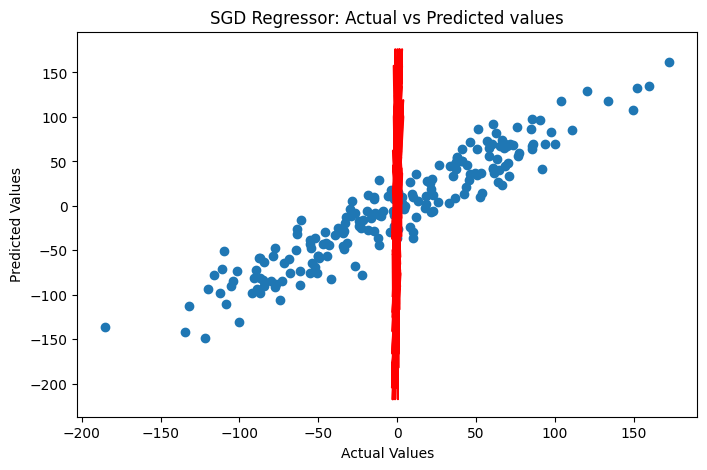

In [83]:
plt.figure(figsize=(8,5))

plt.scatter(y_test,y_pred)
plt.plot(X_train,sgd.predict(X_train),color='red')
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")

plt.title("SGD Regressor: Actual vs Predicted values")

plt.show()


In [79]:
model = sgd.named_steps["sgdregressor"]

print("Weights:", model.coef_)
print("Bias:", model.intercept_)

Weights: [25.57460306 47.16213704 16.70931556 23.18918246 20.78151055]
Bias: [-1.35662132]


This is too noisy as u can see the graph, graph show the discontinuity. Because here we not apply any type of normalization, scaling and etc preprocessing. 
This is the complete impletation of the SGD type of Gradient Descent.

# Mini-Batch Gradient Descent From Scratch

## Objective
Implement Mini-Batch Gradient Descent for Multiple Linear
Regression using Python and NumPy.

### Mathematical Equations

Prediction:

    y_hat = Xw + b

Cost Function:

    J = (1/B) * Σ(y_hat - y)²

Gradient w.r.t Weight:

    dw = (2/B) * X_batch.T @ (y_hat - y_batch)

Gradient w.r.t Bias:

    db = (2/B) * Σ(y_hat - y_batch)

Weight Update:

    w = w - learning_rate * dw

Bias Update:

    b = b - learning_rate * db

### Hyperparameters

- learning_rate
- epochs
- batch_size

## Step 1: Prepare Dataset

We will use our existing training dataset.

X_train = Independent Features

y_train = Actual Target Values

Dataset Shape:

X_train = (samples, features)

y_train = (samples,)

In [35]:
print("X_train Shape:", X_train.shape)
print("y_train Shape:", y_train.shape)

print("Total Samples:", X_train.shape[0])
print("Total Features:",X_train.shape[1])

X_train Shape: (353, 10)
y_train Shape: (353,)
Total Samples: 353
Total Features: 10


## Step 2: Create MiniBatchGradientDescent Class

### Class Responsibilities

1. Initialize weight and bias.
2. Calculate predictions.
3. Calculate cost function.
4. Shuffle the dataset.
5. Divide dataset into mini-batches.
6. Calculate gradients for each mini-batch.
7. Update weight and bias after every batch.
8. Repeat for multiple epochs.

### Methods

- __init__()
- predict()
- compute_cost()
- fit()

Important:

Parameters are updated after processing every mini-batch.

### Using linear Regression

In [62]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred = lr.predict(X_test)
r2 = r2_score(y_test, y_pred)
print(r2)

print(lr.intercept_)
lr.coef_

0.4526027629719197
151.34560453985995


array([  37.90402135, -241.96436231,  542.42875852,  347.70384391,
       -931.48884588,  518.06227698,  163.41998299,  275.31790158,
        736.1988589 ,   48.67065743])

In [51]:
import random

class MBGD:
    def __init__(self, lr=0.01, epoch=100, batch_size=32,random_state=None):
        self.lr = lr
        self.epoch = epoch
        self.batch_size = batch_size
        self.w = None
        self.b = None
        self.random_state = random_state
        
        self.cost_history = []
        
        # Step1: Prediction
    def predict(self,X_test):
        return np.dot(X_test,self.w) + self.b
        
    
        
    #step3: Training using MBGD
    def fit(self,X_train,y_train):
        self.w = np.ones(X_train.shape[1])
        self.b = 0
        
        for i in range(self.epoch):
            for j in range(int(X_train.shape[0]/self.batch_size)):
                idx = random.sample(range(X_train.shape[0]),self.batch_size)
                y_pred = np.dot(X_train[idx],self.w) + self.b
                
                db = -2 * np.mean(y_train[idx] - y_pred)
                dw = -2 * np.dot((y_train[idx]- y_pred),X_train[idx])
                
                self.w = self.w - (self.lr*dw)
                self.b = self.b - (self.lr*db)
        print(self.b,self.w)
            
                
                
        
        return self
                    
    

## Step 3: Model Training

We will train our model using Mini-Batch Gradient Descent.

Hyperparameters:

- Learning Rate = 0.001
- Epochs = 100
- Batch Size = 32

Each mini-batch will update the model parameters once.

In [67]:
model = MBGD(
    lr=0.01,
    epoch=70,
    batch_size=int(X_train.shape[0]/10),
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)
print(r2)

151.95954727465724 [  62.66283496 -128.16700449  413.167555    282.82299751  -30.39539981
  -70.14289442 -198.68341571  147.81397917  313.99484311  143.49126264]
0.45289470619201744
